# Employee Attrition Prediction Using Machine Learning

## Domain: Human Resource Management (HR Analytics)

### Objective
To analyze the demographic, job-related and satisfaction characteristics of employees and develop a machine learning model to predict whether an employee is likely to leave the company.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('HR_Employee_Attrition.csv', encoding='utf-8-sig')

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
df.shape

(1470, 35)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [4]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [5]:
df.describe(include='object')

/tmp/ipykernel_86/87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


In [6]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [7]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

Data cleaning

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df[['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']].head()

,EmployeeCount,EmployeeNumber,Over18,StandardHours
0,1,1,Y,80
1,1,2,Y,80
2,1,4,Y,80
3,1,5,Y,80
4,1,7,Y,80


In [10]:
# EmployeeCount, Over18 and StandardHours have the same value in every row,
# and EmployeeNumber is only an ID - none of them help in the analysis
df[['EmployeeCount', 'Over18', 'StandardHours']].nunique()

EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64

In [11]:
df = df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis=1, errors='ignore')

In [12]:
# Convert target variable to 0/1 (Yes = employee left, No = employee stayed)
df['Attrition'] = df['Attrition'].map({'No': 0, 'Yes': 1})
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [13]:
df.shape

(1470, 31)

Descriptive Statistics

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
Attrition,1470.0,0.161224,0.367863,0.0,0.0,0.0,0.00,1.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.00,5.0
JobSatisfaction,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.00,4.0


In [15]:
df['Age'].describe()

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64

In [16]:
df['MonthlyIncome'].describe()

count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64

In [17]:
df['DistanceFromHome'].describe()

count    1470.000000
mean        9.192517
std         8.106864
min         1.000000
25%         2.000000
50%         7.000000
75%        14.000000
max        29.000000
Name: DistanceFromHome, dtype: float64

In [18]:
df['YearsAtCompany'].describe()

count    1470.000000
mean        7.008163
std         6.126525
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        40.000000
Name: YearsAtCompany, dtype: float64

In [19]:
df['TotalWorkingYears'].describe()

count    1470.000000
mean       11.279592
std         7.780782
min         0.000000
25%         6.000000
50%        10.000000
75%        15.000000
max        40.000000
Name: TotalWorkingYears, dtype: float64

Distribution graphs

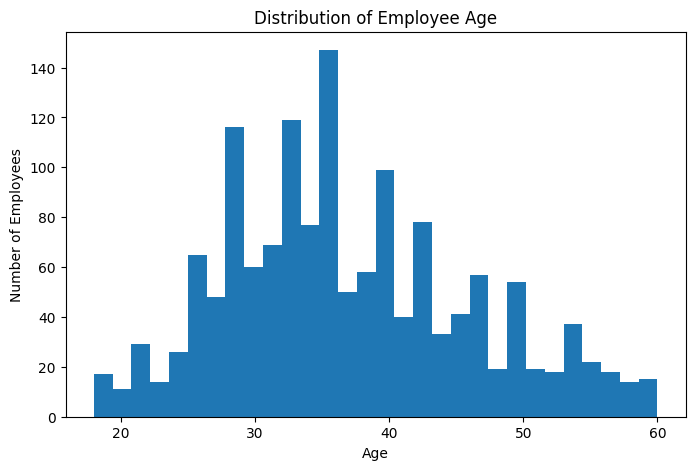

In [20]:
plt.figure(figsize=(8,5))
plt.hist(df['Age'], bins=30)
plt.xlabel('Age')
plt.ylabel('Number of Employees')
plt.title('Distribution of Employee Age')
plt.show()

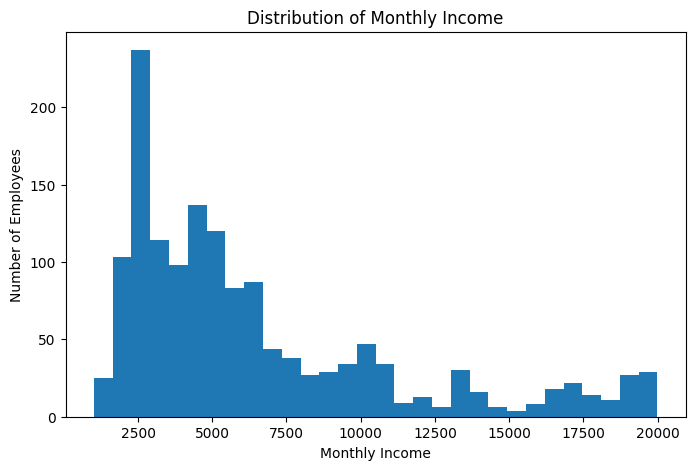

In [21]:
plt.figure(figsize=(8,5))
plt.hist(df['MonthlyIncome'], bins=30)
plt.xlabel('Monthly Income')
plt.ylabel('Number of Employees')
plt.title('Distribution of Monthly Income')
plt.show()

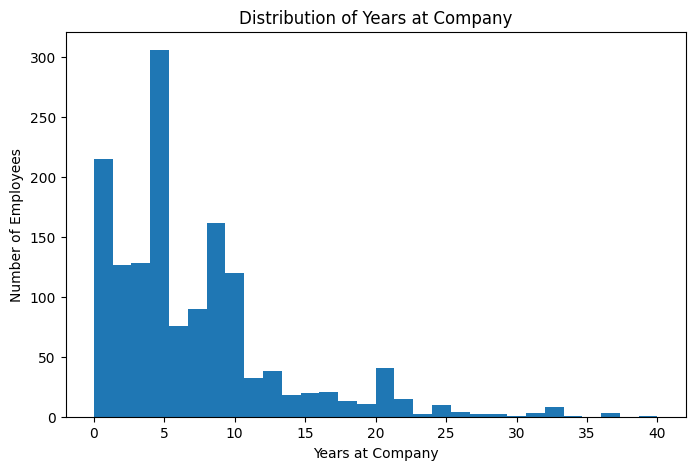

In [22]:
plt.figure(figsize=(8,5))
plt.hist(df['YearsAtCompany'], bins=30)
plt.xlabel('Years at Company')
plt.ylabel('Number of Employees')
plt.title('Distribution of Years at Company')
plt.show()

Categorical Frequency Distribution

In [23]:
df['Department'].value_counts()

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

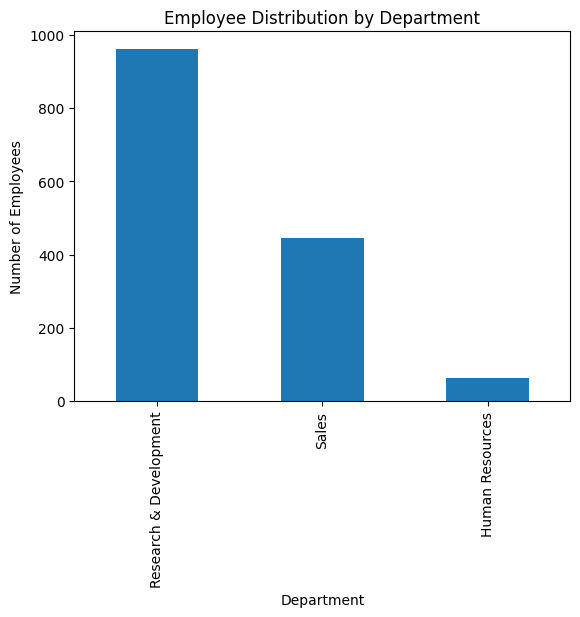

In [24]:
df['Department'].value_counts().plot(kind='bar')
plt.title('Employee Distribution by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.show()

In [25]:
df['JobRole'].value_counts()

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

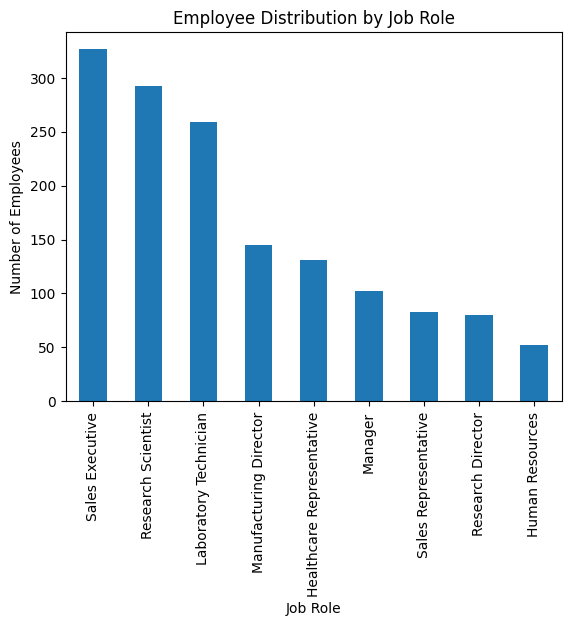

In [26]:
df['JobRole'].value_counts().plot(kind='bar')
plt.title('Employee Distribution by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Number of Employees')
plt.show()

In [27]:
df['Gender'].value_counts()

Gender
Male      882
Female    588
Name: count, dtype: int64

In [28]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64

In [29]:
df['BusinessTravel'].value_counts()

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

In [30]:
df['OverTime'].value_counts()

OverTime
No     1054
Yes     416
Name: count, dtype: int64

Analyze attrition

In [31]:
df['Attrition'].value_counts()

Attrition
0    1233
1     237
Name: count, dtype: int64

In [32]:
df['Attrition'].value_counts(normalize=True) * 100

Attrition
0    83.877551
1    16.122449
Name: proportion, dtype: float64

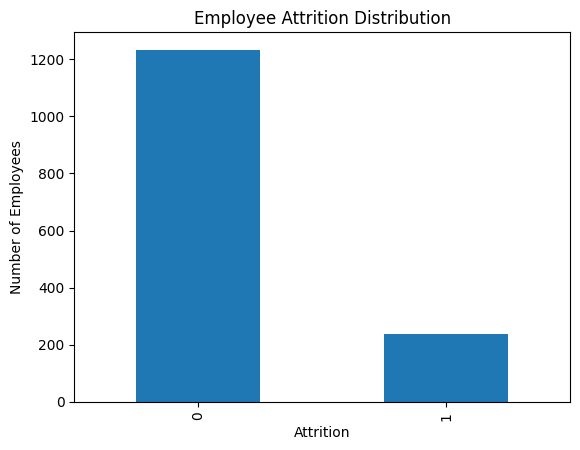

In [33]:
df['Attrition'].value_counts().plot(kind='bar')
plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')
plt.show()

Compare variables against attrition

In [34]:
pd.crosstab(df['OverTime'], df['Attrition'], normalize='index') * 100

Attrition,0,1
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


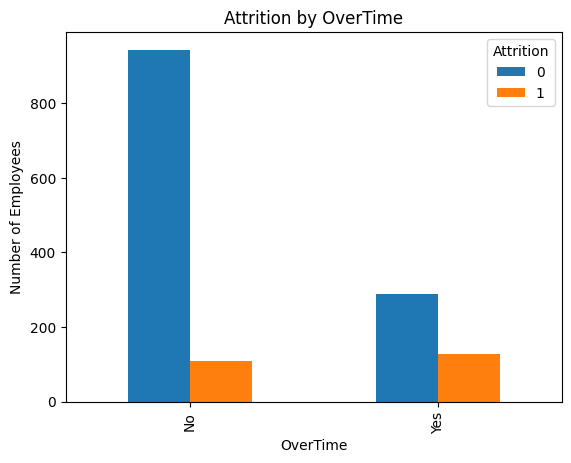

In [35]:
pd.crosstab(df['OverTime'], df['Attrition']).plot(kind='bar')
plt.title('Attrition by OverTime')
plt.xlabel('OverTime')
plt.ylabel('Number of Employees')
plt.show()

In [36]:
pd.crosstab(df['BusinessTravel'], df['Attrition'], normalize='index') * 100

Attrition,0,1
BusinessTravel,,
Non-Travel,92.000000,8.000000
Travel_Frequently,75.090253,24.909747
Travel_Rarely,85.043145,14.956855


In [37]:
pd.crosstab(df['MaritalStatus'], df['Attrition'], normalize='index') * 100

Attrition,0,1
MaritalStatus,,
Divorced,89.908257,10.091743
Married,87.518574,12.481426
Single,74.468085,25.531915


In [38]:
pd.crosstab(df['Department'], df['Attrition'], normalize='index') * 100

Attrition,0,1
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


In [39]:
pd.crosstab(df['JobRole'], df['Attrition'], normalize='index') * 100

Attrition,0,1
JobRole,,
Healthcare Representative,93.129771,6.870229
Human Resources,76.923077,23.076923
Laboratory Technician,76.061776,23.938224
Manager,95.098039,4.901961
Manufacturing Director,93.103448,6.896552
Research Director,97.500000,2.500000
Research Scientist,83.904110,16.095890
Sales Executive,82.515337,17.484663
Sales Representative,60.240964,39.759036


In [40]:
pd.crosstab(df['Gender'], df['Attrition'], normalize='index') * 100

Attrition,0,1
Gender,,
Female,85.204082,14.795918
Male,82.993197,17.006803


Numerical variables vs attrition

In [41]:
df.groupby('Attrition')['Age'].mean()

Attrition
0    37.561233
1    33.607595
Name: Age, dtype: float64

In [42]:
df.groupby('Attrition')['MonthlyIncome'].mean()

Attrition
0    6832.739659
1    4787.092827
Name: MonthlyIncome, dtype: float64

In [43]:
df.groupby('Attrition')['DistanceFromHome'].mean()

Attrition
0     8.915653
1    10.632911
Name: DistanceFromHome, dtype: float64

In [44]:
df.groupby('Attrition')['YearsAtCompany'].mean()

Attrition
0    7.369019
1    5.130802
Name: YearsAtCompany, dtype: float64

In [45]:
df.groupby('Attrition')['TotalWorkingYears'].mean()

Attrition
0    11.862936
1     8.244726
Name: TotalWorkingYears, dtype: float64

Boxplots

<Figure size 800x500 with 0 Axes>

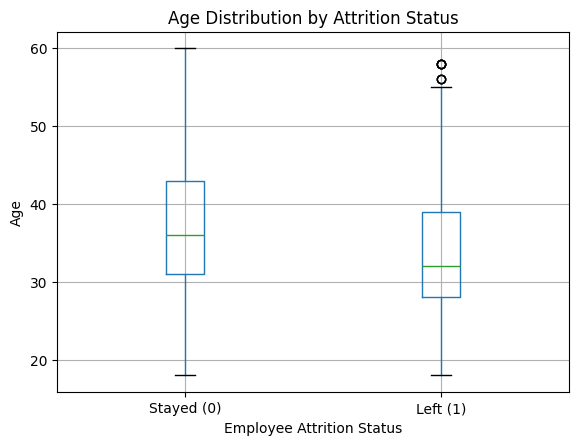

In [46]:
plt.figure(figsize=(8,5))

df.boxplot(column='Age', by='Attrition')

plt.title('Age Distribution by Attrition Status')
plt.suptitle('')
plt.xlabel('Employee Attrition Status')
plt.ylabel('Age')

plt.xticks([1, 2], ['Stayed (0)', 'Left (1)'])

plt.show()

<Figure size 800x500 with 0 Axes>

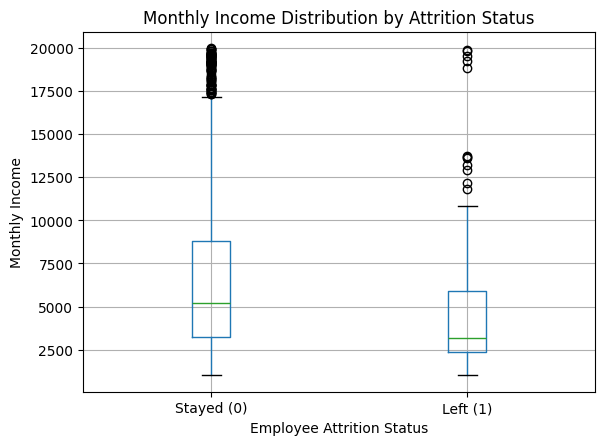

In [47]:
plt.figure(figsize=(8,5))

df.boxplot(column='MonthlyIncome', by='Attrition')

plt.title('Monthly Income Distribution by Attrition Status')
plt.suptitle('')
plt.xlabel('Employee Attrition Status')
plt.ylabel('Monthly Income')

plt.xticks([1, 2], ['Stayed (0)', 'Left (1)'])

plt.show()

<Figure size 800x500 with 0 Axes>

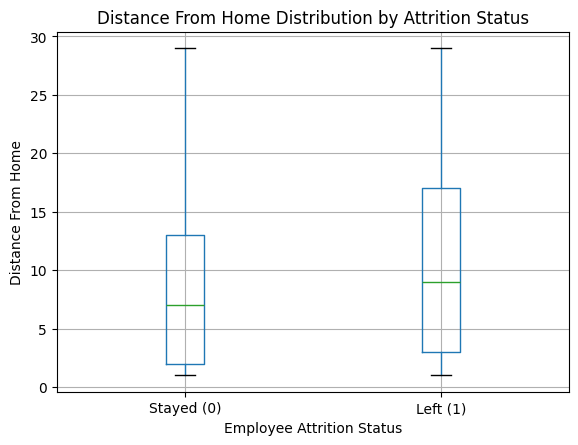

In [48]:
plt.figure(figsize=(8,5))

df.boxplot(column='DistanceFromHome', by='Attrition')

plt.title('Distance From Home Distribution by Attrition Status')
plt.suptitle('')
plt.xlabel('Employee Attrition Status')
plt.ylabel('Distance From Home')

plt.xticks([1, 2], ['Stayed (0)', 'Left (1)'])

plt.show()

<Figure size 800x500 with 0 Axes>

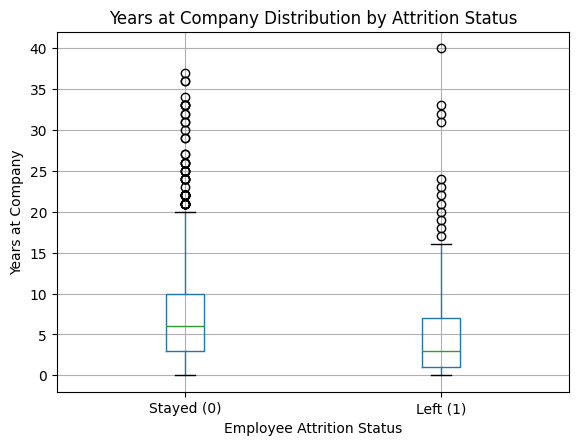

In [49]:
plt.figure(figsize=(8,5))

df.boxplot(column='YearsAtCompany', by='Attrition')

plt.title('Years at Company Distribution by Attrition Status')
plt.suptitle('')
plt.xlabel('Employee Attrition Status')
plt.ylabel('Years at Company')

plt.xticks([1, 2], ['Stayed (0)', 'Left (1)'])

plt.show()

<Figure size 800x500 with 0 Axes>

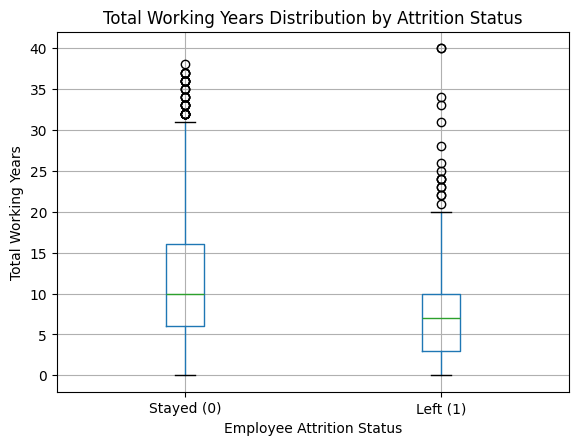

In [50]:
plt.figure(figsize=(8,5))

df.boxplot(column='TotalWorkingYears', by='Attrition')

plt.title('Total Working Years Distribution by Attrition Status')
plt.suptitle('')
plt.xlabel('Employee Attrition Status')
plt.ylabel('Total Working Years')

plt.xticks([1, 2], ['Stayed (0)', 'Left (1)'])

plt.show()

<Figure size 800x500 with 0 Axes>

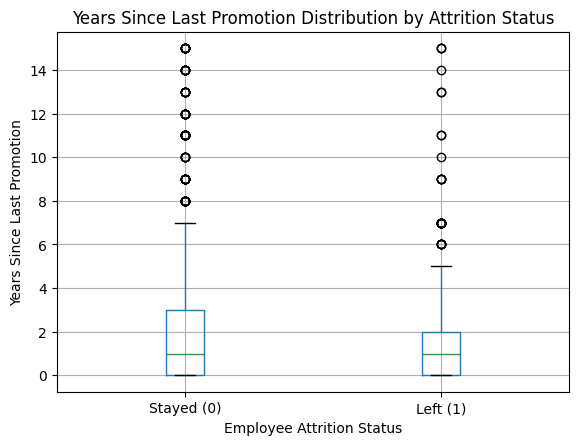

In [51]:
plt.figure(figsize=(8,5))

df.boxplot(column='YearsSinceLastPromotion', by='Attrition')

plt.title('Years Since Last Promotion Distribution by Attrition Status')
plt.suptitle('')
plt.xlabel('Employee Attrition Status')
plt.ylabel('Years Since Last Promotion')

plt.xticks([1, 2], ['Stayed (0)', 'Left (1)'])

plt.show()

Correlation Analysis

In [52]:
# Select numerical variables
numeric_cols = df.select_dtypes(include=np.number).columns

numeric_cols

Index(['Age', 'Attrition', 'DailyRate', 'DistanceFromHome', 'Education',
       'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel',
       'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='str')

In [53]:
# Calculate correlation matrix
correlation_matrix = df[numeric_cols].corr()

correlation_matrix

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.000000,-0.159205,0.010661,-0.001686,0.208034,0.010146,0.024287,0.029820,0.509604,-0.004892,...,0.001904,0.053535,0.037510,0.680381,-0.019621,-0.021490,0.311309,0.212901,0.216513,0.202089
Attrition,-0.159205,1.000000,-0.056652,0.077924,-0.031373,-0.103369,-0.006846,-0.130016,-0.169105,-0.103481,...,0.002889,-0.045872,-0.137145,-0.171063,-0.059478,-0.063939,-0.134392,-0.160545,-0.033019,-0.156199
DailyRate,0.010661,-0.056652,1.000000,-0.004985,-0.016806,0.018355,0.023381,0.046135,0.002966,0.030571,...,0.000473,0.007846,0.042143,0.014515,0.002453,-0.037848,-0.034055,0.009932,-0.033229,-0.026363
DistanceFromHome,-0.001686,0.077924,-0.004985,1.000000,0.021042,-0.016075,0.031131,0.008783,0.005303,-0.003669,...,0.027110,0.006557,0.044872,0.004628,-0.036942,-0.026556,0.009508,0.018845,0.010029,0.014406
Education,0.208034,-0.031373,-0.016806,0.021042,1.000000,-0.027128,0.016775,0.042438,0.101589,-0.011296,...,-0.024539,-0.009118,0.018422,0.148280,-0.025100,0.009819,0.069114,0.060236,0.054254,0.069065
EnvironmentSatisfaction,0.010146,-0.103369,0.018355,-0.016075,-0.027128,1.000000,-0.049857,-0.008278,0.001212,-0.006784,...,-0.029548,0.007665,0.003432,-0.002693,-0.019359,0.027627,0.001458,0.018007,0.016194,-0.004999
HourlyRate,0.024287,-0.006846,0.023381,0.031131,0.016775,-0.049857,1.000000,0.042861,-0.027853,-0.071335,...,-0.002172,0.001330,0.050263,-0.002334,-0.008548,-0.004607,-0.019582,-0.024106,-0.026716,-0.020123
JobInvolvement,0.029820,-0.130016,0.046135,0.008783,0.042438,-0.008278,0.042861,1.000000,-0.012630,-0.021476,...,-0.029071,0.034297,0.021523,-0.005533,-0.015338,-0.014617,-0.021355,0.008717,-0.024184,0.025976
JobLevel,0.509604,-0.169105,0.002966,0.005303,0.101589,0.001212,-0.027853,-0.012630,1.000000,-0.001944,...,-0.021222,0.021642,0.013984,0.782208,-0.018191,0.037818,0.534739,0.389447,0.353885,0.375281
JobSatisfaction,-0.004892,-0.103481,0.030571,-0.003669,-0.011296,-0.006784,-0.071335,-0.021476,-0.001944,1.000000,...,0.002297,-0.012454,0.010690,-0.020185,-0.005779,-0.019459,-0.003803,-0.002305,-0.018214,-0.027656


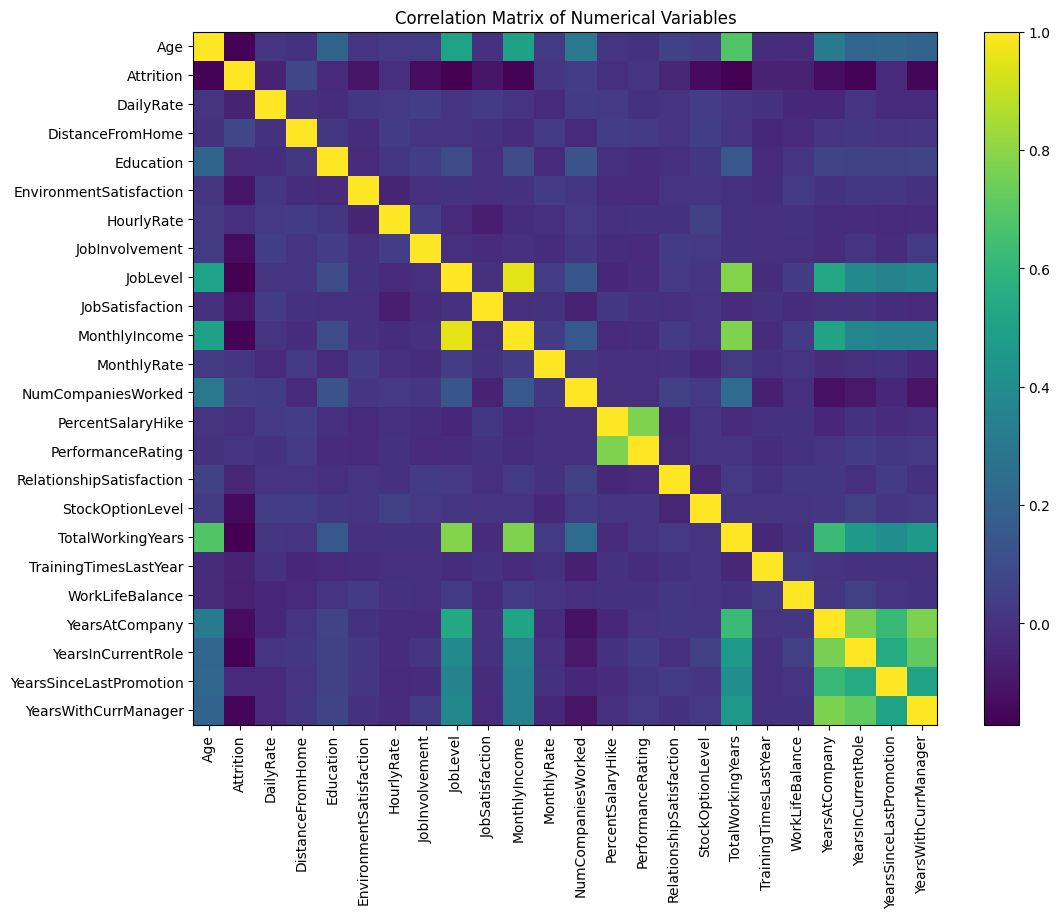

In [54]:
plt.figure(figsize=(12,9))

plt.imshow(correlation_matrix, aspect='auto')
plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title('Correlation Matrix of Numerical Variables')

plt.show()

In [55]:
# Correlation of numerical variables with attrition
attrition_correlation = correlation_matrix['Attrition'].sort_values(ascending=False)

attrition_correlation

Attrition                   1.000000
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
DailyRate                  -0.056652
TrainingTimesLastYear      -0.059478
WorkLifeBalance            -0.063939
EnvironmentSatisfaction    -0.103369
JobSatisfaction            -0.103481
JobInvolvement             -0.130016
YearsAtCompany             -0.134392
StockOptionLevel           -0.137145
YearsWithCurrManager       -0.156199
Age                        -0.159205
MonthlyIncome              -0.159840
YearsInCurrentRole         -0.160545
JobLevel                   -0.169105
TotalWorkingYears          -0.171063
Name: Attrition, dtype: float64

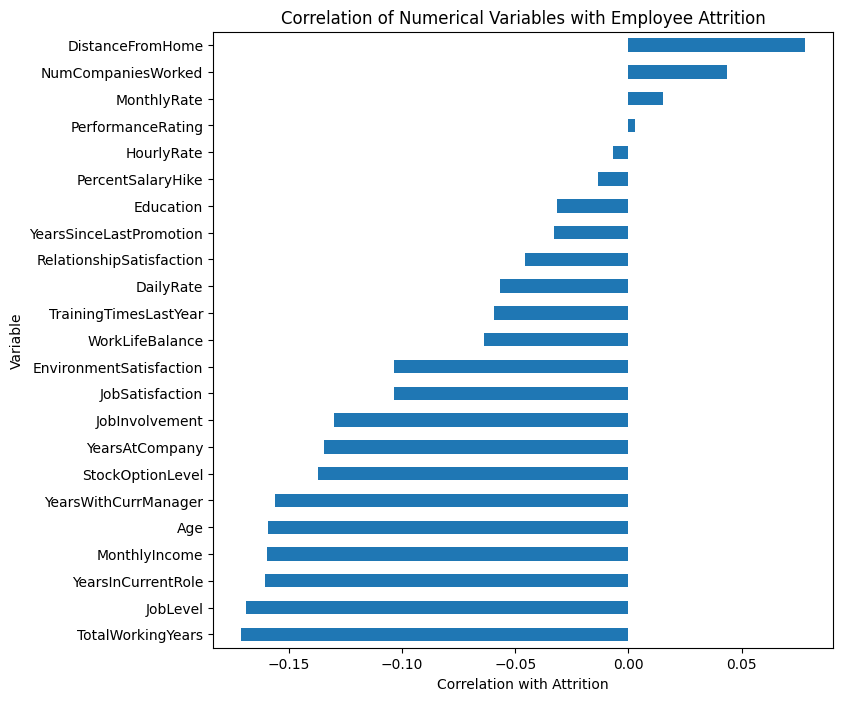

In [56]:
plt.figure(figsize=(8,8))

attrition_correlation.drop('Attrition').sort_values().plot(kind='barh')

plt.title('Correlation of Numerical Variables with Employee Attrition')
plt.xlabel('Correlation with Attrition')
plt.ylabel('Variable')

plt.show()

In [57]:
age_attr = df.groupby('Attrition')['Age'].mean()

age_attr

Attrition
0    37.561233
1    33.607595
Name: Age, dtype: float64

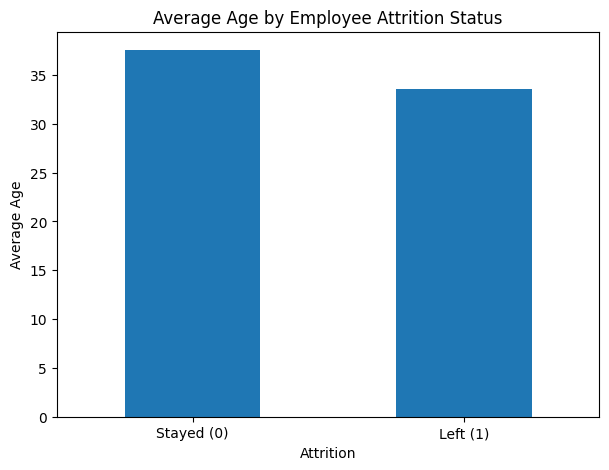

In [58]:
age_attr.plot(kind='bar', figsize=(7,5))

plt.title('Average Age by Employee Attrition Status')
plt.xlabel('Attrition')
plt.ylabel('Average Age')

plt.xticks([0,1], ['Stayed (0)', 'Left (1)'], rotation=0)

plt.show()

In [59]:
income_attr = df.groupby('Attrition')['MonthlyIncome'].mean()

income_attr

Attrition
0    6832.739659
1    4787.092827
Name: MonthlyIncome, dtype: float64

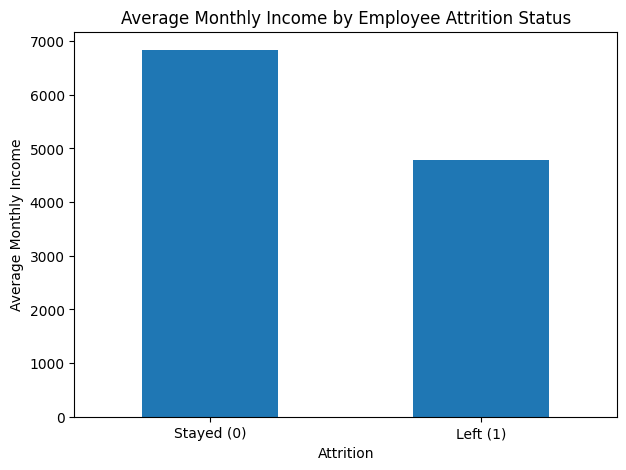

In [60]:
income_attr.plot(kind='bar', figsize=(7,5))

plt.title('Average Monthly Income by Employee Attrition Status')
plt.xlabel('Attrition')
plt.ylabel('Average Monthly Income')

plt.xticks([0,1], ['Stayed (0)', 'Left (1)'], rotation=0)

plt.show()

In [61]:
tenure_attr = df.groupby('Attrition')['YearsAtCompany'].mean()

tenure_attr

Attrition
0    7.369019
1    5.130802
Name: YearsAtCompany, dtype: float64

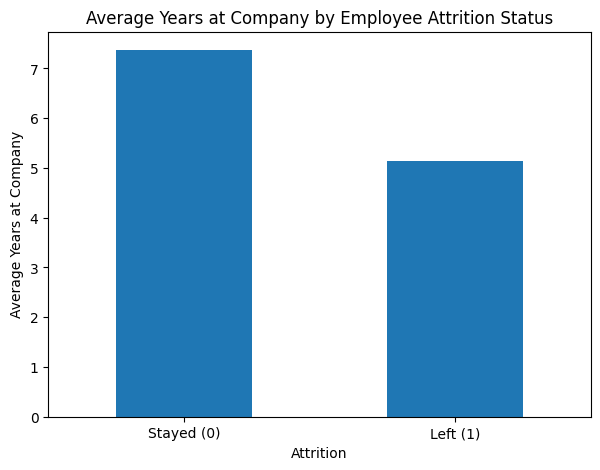

In [62]:
tenure_attr.plot(kind='bar', figsize=(7,5))

plt.title('Average Years at Company by Employee Attrition Status')
plt.xlabel('Attrition')
plt.ylabel('Average Years at Company')

plt.xticks([0,1], ['Stayed (0)', 'Left (1)'], rotation=0)

plt.show()

In [63]:
distance_attr = df.groupby('Attrition')['DistanceFromHome'].mean()

distance_attr

Attrition
0     8.915653
1    10.632911
Name: DistanceFromHome, dtype: float64

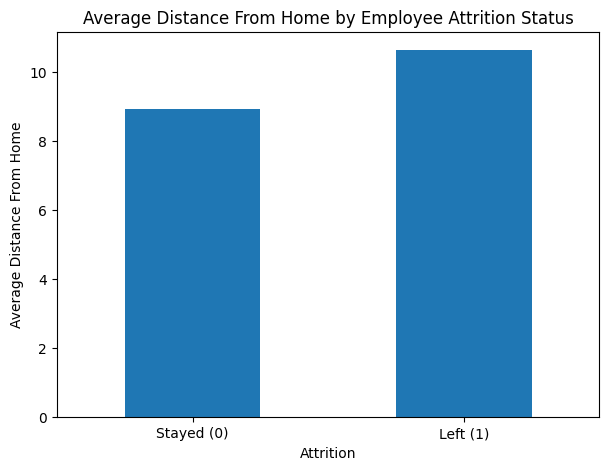

In [64]:
distance_attr.plot(kind='bar', figsize=(7,5))

plt.title('Average Distance From Home by Employee Attrition Status')
plt.xlabel('Attrition')
plt.ylabel('Average Distance From Home')

plt.xticks([0,1], ['Stayed (0)', 'Left (1)'], rotation=0)

plt.show()

In [65]:
overtime_attr = pd.crosstab(
    df['OverTime'],
    df['Attrition'],
    normalize='index'
) * 100

overtime_attr

Attrition,0,1
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


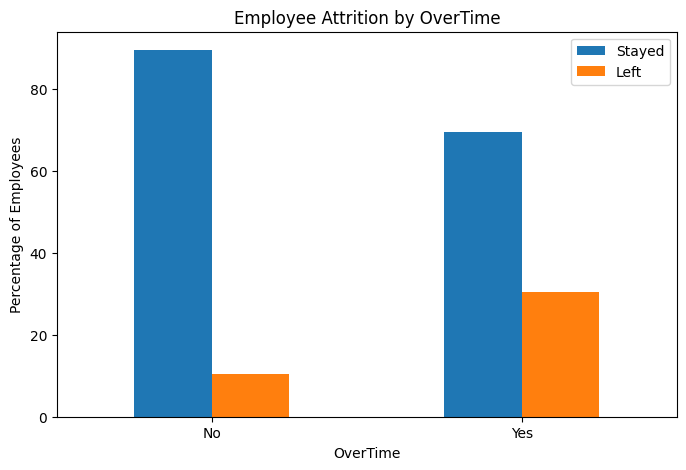

In [66]:
overtime_attr.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Employee Attrition by OverTime')
plt.xlabel('OverTime')
plt.ylabel('Percentage of Employees')

plt.xticks(rotation=0)

plt.legend(['Stayed', 'Left'])

plt.show()

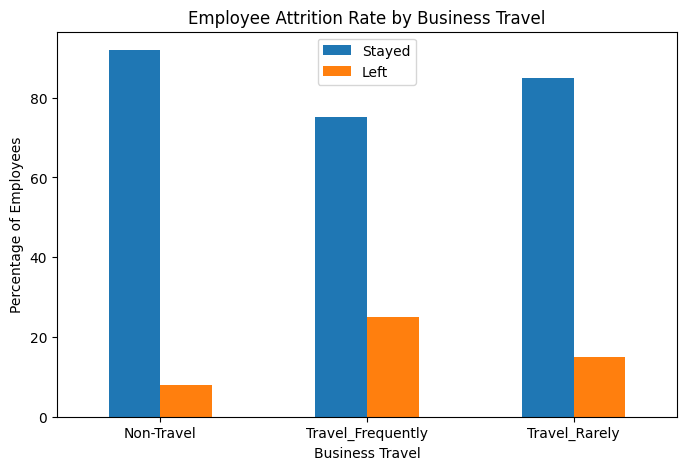

In [67]:
travel_attr = pd.crosstab(
    df['BusinessTravel'],
    df['Attrition'],
    normalize='index'
) * 100

travel_attr

travel_attr.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Employee Attrition Rate by Business Travel')
plt.xlabel('Business Travel')
plt.ylabel('Percentage of Employees')

plt.xticks(rotation=0)

plt.legend(['Stayed', 'Left'])

plt.show()

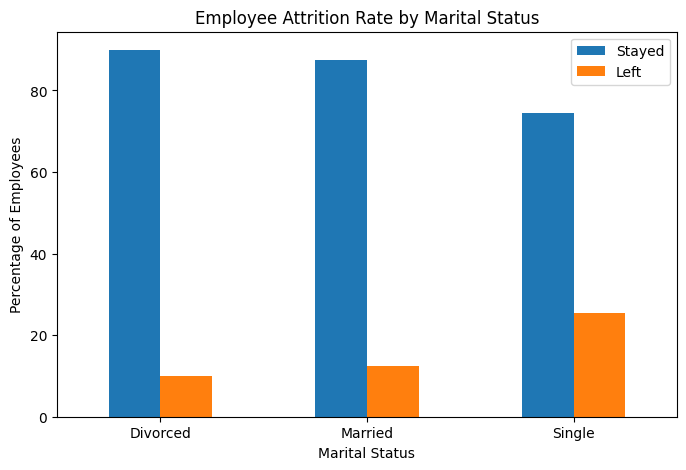

In [68]:
marital_attr = pd.crosstab(
    df['MaritalStatus'],
    df['Attrition'],
    normalize='index'
) * 100

marital_attr

marital_attr.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Employee Attrition Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Percentage of Employees')

plt.xticks(rotation=0)

plt.legend(['Stayed', 'Left'])

plt.show()

summary table

In [69]:
summary = df.groupby('Attrition').agg({
    'Age': 'mean',
    'MonthlyIncome': 'mean',
    'DistanceFromHome': 'mean',
    'YearsAtCompany': 'mean',
    'TotalWorkingYears': 'mean',
    'YearsSinceLastPromotion': 'mean'
})

summary

,Age,MonthlyIncome,DistanceFromHome,YearsAtCompany,TotalWorkingYears,YearsSinceLastPromotion
Attrition,,,,,,
0,37.561233,6832.739659,8.915653,7.369019,11.862936,2.234388
1,33.607595,4787.092827,10.632911,5.130802,8.244726,1.945148


Machine Learning Preparation

In [70]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [71]:
df.shape

(1470, 31)

In [72]:
# Department is already contained in JobRole (e.g. every Sales Representative is in Sales),
# so it is dropped before encoding to avoid duplicate information in the model
df_ml = df.drop('Department', axis=1)

df_ml = pd.get_dummies(
    df_ml,
    columns=['BusinessTravel', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime'],
    drop_first=True
)

df_ml.head()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1,1102,1,2,2,94,3,2,4,...,False,False,False,False,False,True,False,False,True,True
1,49,0,279,8,1,3,61,2,2,2,...,False,False,False,False,True,False,False,True,False,False
2,37,1,1373,2,2,4,92,2,1,3,...,True,False,False,False,False,False,False,False,True,True
3,33,0,1392,3,4,4,56,3,1,3,...,False,False,False,False,True,False,False,True,False,True
4,27,0,591,2,1,1,40,3,1,2,...,True,False,False,False,False,False,False,True,False,False


In [73]:
df_ml.columns

Index(['Age', 'Attrition', 'DailyRate', 'DistanceFromHome', 'Education',
       'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel',
       'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager',
       'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely',
       'EducationField_Life Sciences', 'EducationField_Marketing',
       'EducationField_Medical', 'EducationField_Other',
       'EducationField_Technical Degree', 'Gender_Male',
       'JobRole_Human Resources', 'JobRole_Laboratory Technician',
       'JobRole_Manager', 'JobRole_Manufacturing Director',
       'JobRole_Research Director', 'JobRole_Research Scientist',
       'JobRole_Sales Executive', 'JobRole_Sal

Define X and y

In [74]:
X = df_ml.drop('Attrition', axis=1)

y = df_ml['Attrition']

In [75]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1470, 42)
y shape: (1470,)


Train-Test Split

In [76]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1176, 42)
Testing data: (294, 42)


Logistic Regression

In [77]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [78]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [79]:
y_pred_log = log_model.predict(X_test_scaled)

y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [80]:
import statsmodels.api as sm

In [81]:
X = X.astype(int)

# Add constant/intercept
X_stats = sm.add_constant(X)

# Fit logistic regression
logit_model = sm.Logit(y, X_stats)

logit_result = logit_model.fit(maxiter=200)

print(logit_result.summary())

Optimization terminated successfully.
         Current function value: 0.292629
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:              Attrition   No. Observations:                 1470
Model:                          Logit   Df Residuals:                     1427
Method:                           MLE   Df Model:                           42
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                  0.3375
Time:                        08:30:28   Log-Likelihood:                -430.16
converged:                       True   LL-Null:                       -649.29
Covariance Type:            nonrobust   LLR p-value:                 2.012e-67
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const                                2.0017      1.598      1.25

In [82]:
# Get coefficients
coefficients = logit_result.params

# Calculate Odds Ratios
odds_ratios = np.exp(coefficients)

# Create confidence intervals
conf_int = logit_result.conf_int()

# Convert confidence intervals to odds ratio scale
conf_int_odds = np.exp(conf_int)

# Create final table
odds_ratio_table = pd.DataFrame({
    'Coefficient': coefficients,
    'Odds Ratio': odds_ratios,
    'Lower CI': conf_int_odds[0],
    'Upper CI': conf_int_odds[1],
    'P-value': logit_result.pvalues
})

odds_ratio_table

,Coefficient,Odds Ratio,Lower CI,Upper CI,P-value
const,2.001652,7.401272,0.322892,169.650667,2.103618e-01
Age,-0.030949,0.969525,0.944138,0.995595,2.224976e-02
DailyRate,-0.000283,0.999717,0.999286,1.000148,1.983284e-01
DistanceFromHome,0.045413,1.046460,1.024621,1.068765,2.440106e-05
Education,0.002544,1.002547,0.844250,1.190525,9.768570e-01
EnvironmentSatisfaction,-0.434474,0.647605,0.550563,0.761752,1.558735e-07
HourlyRate,0.001068,1.001069,0.992459,1.009754,8.085042e-01
JobInvolvement,-0.529052,0.589163,0.463546,0.748821,1.531047e-05
JobLevel,-0.090499,0.913475,0.491391,1.698112,7.748154e-01
JobSatisfaction,-0.413394,0.661402,0.563832,0.775856,3.844561e-07


In [83]:
odds_ratio_table = odds_ratio_table.round(4)

odds_ratio_table

,Coefficient,Odds Ratio,Lower CI,Upper CI,P-value
const,2.0017,7.4013,0.3229,169.6507,0.2104
Age,-0.0309,0.9695,0.9441,0.9956,0.0222
DailyRate,-0.0003,0.9997,0.9993,1.0001,0.1983
DistanceFromHome,0.0454,1.0465,1.0246,1.0688,0.0000
Education,0.0025,1.0025,0.8442,1.1905,0.9769
EnvironmentSatisfaction,-0.4345,0.6476,0.5506,0.7618,0.0000
HourlyRate,0.0011,1.0011,0.9925,1.0098,0.8085
JobInvolvement,-0.5291,0.5892,0.4635,0.7488,0.0000
JobLevel,-0.0905,0.9135,0.4914,1.6981,0.7748
JobSatisfaction,-0.4134,0.6614,0.5638,0.7759,0.0000


Stepwise Logistic Regression

In [84]:
def backward_stepwise_logistic(X, y, significance_level=0.05):

    X_selected = X.copy()

    while True:
        model = sm.Logit(y, X_selected).fit(disp=0, maxiter=200)

        p_values = model.pvalues.drop('const')
        max_p_value = p_values.max()

        if max_p_value > significance_level:
            variable_to_remove = p_values.idxmax()

            print(
                f"Removing {variable_to_remove} "
                f"(p-value = {max_p_value:.4f})"
            )

            X_selected = X_selected.drop(
                columns=[variable_to_remove]
            )
        else:
            break

    final_model = sm.Logit(y, X_selected).fit(disp=0, maxiter=200)

    return X_selected, final_model

In [85]:
X_stepwise = sm.add_constant(X)

X_stepwise_selected, stepwise_final = backward_stepwise_logistic(
    X_stepwise,
    y,
    significance_level=0.05
)

Removing Education (p-value = 0.9769)
Removing MonthlyIncome (p-value = 0.8905)
Removing EducationField_Marketing (p-value = 0.8342)
Removing HourlyRate (p-value = 0.8114)
Removing JobLevel (p-value = 0.7888)
Removing JobRole_Manager (p-value = 0.8188)
Removing PerformanceRating (p-value = 0.7490)
Removing JobRole_Manufacturing Director (p-value = 0.7158)
Removing MonthlyRate (p-value = 0.7169)
Removing PercentSalaryHike (p-value = 0.6227)
Removing EducationField_Other (p-value = 0.2542)
Removing EducationField_Life Sciences (p-value = 0.3565)


Removing EducationField_Medical (p-value = 0.3985)
Removing MaritalStatus_Married (p-value = 0.2264)
Removing JobRole_Research Scientist (p-value = 0.1761)
Removing DailyRate (p-value = 0.1314)
Removing JobRole_Research Director (p-value = 0.1124)
Removing StockOptionLevel (p-value = 0.0826)


In [86]:
print("Variables selected by Stepwise Logistic Regression:")
print(X_stepwise_selected.columns.tolist())

Variables selected by Stepwise Logistic Regression:
['const', 'Age', 'DistanceFromHome', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction', 'NumCompaniesWorked', 'RelationshipSatisfaction', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely', 'EducationField_Technical Degree', 'Gender_Male', 'JobRole_Human Resources', 'JobRole_Laboratory Technician', 'JobRole_Sales Executive', 'JobRole_Sales Representative', 'MaritalStatus_Single', 'OverTime_Yes']


In [87]:
print(stepwise_final.summary())

                           Logit Regression Results                           
Dep. Variable:              Attrition   No. Observations:                 1470
Model:                          Logit   Df Residuals:                     1445
Method:                           MLE   Df Model:                           24
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                  0.3253
Time:                        08:30:28   Log-Likelihood:                -438.06
converged:                       True   LL-Null:                       -649.29
Covariance Type:            nonrobust   LLR p-value:                 1.810e-74
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const                                1.8319      0.818      2.239      0.025       0.228       3.436
Age                                 -0.0298      0.013     -2.257

In [88]:
stepwise_coefficients = stepwise_final.params

stepwise_odds_ratios = np.exp(stepwise_coefficients)

stepwise_conf_int = stepwise_final.conf_int()

stepwise_conf_int_odds = np.exp(stepwise_conf_int)

stepwise_odds_ratio_table = pd.DataFrame({
    'Coefficient': stepwise_coefficients,
    'Odds Ratio': stepwise_odds_ratios,
    'Lower CI': stepwise_conf_int_odds[0],
    'Upper CI': stepwise_conf_int_odds[1],
    'P-value': stepwise_final.pvalues
})

stepwise_odds_ratio_table.round(4)

,Coefficient,Odds Ratio,Lower CI,Upper CI,P-value
const,1.8319,6.2455,1.2562,31.0523,0.0252
Age,-0.0298,0.9706,0.9458,0.9961,0.0240
DistanceFromHome,0.0437,1.0446,1.0233,1.0664,0.0000
EnvironmentSatisfaction,-0.4323,0.6490,0.5535,0.7610,0.0000
JobInvolvement,-0.5264,0.5907,0.4664,0.7482,0.0000
JobSatisfaction,-0.4233,0.6549,0.5600,0.7659,0.0000
NumCompaniesWorked,0.1886,1.2076,1.1218,1.2999,0.0000
RelationshipSatisfaction,-0.2505,0.7784,0.6639,0.9128,0.0020
TotalWorkingYears,-0.0795,0.9236,0.8797,0.9697,0.0014
TrainingTimesLastYear,-0.2011,0.8178,0.7105,0.9413,0.0051


In [89]:
selected_features = [
    col for col in X_stepwise_selected.columns
    if col != 'const'
]

print("Selected Features:")
print(selected_features)

Selected Features:
['Age', 'DistanceFromHome', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction', 'NumCompaniesWorked', 'RelationshipSatisfaction', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely', 'EducationField_Technical Degree', 'Gender_Male', 'JobRole_Human Resources', 'JobRole_Laboratory Technician', 'JobRole_Sales Executive', 'JobRole_Sales Representative', 'MaritalStatus_Single', 'OverTime_Yes']


In [90]:
X_train_stepwise = X_train[selected_features]
X_test_stepwise = X_test[selected_features]

print("Training shape:", X_train_stepwise.shape)
print("Testing shape :", X_test_stepwise.shape)

Training shape: (1176, 24)
Testing shape : (294, 24)


In [91]:
from sklearn.preprocessing import StandardScaler

stepwise_scaler = StandardScaler()

X_train_stepwise_scaled = stepwise_scaler.fit_transform(
    X_train_stepwise
)

X_test_stepwise_scaled = stepwise_scaler.transform(
    X_test_stepwise
)

In [92]:
from sklearn.linear_model import LogisticRegression

stepwise_log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

stepwise_log_model.fit(
    X_train_stepwise_scaled,
    y_train
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [93]:
y_pred_stepwise = stepwise_log_model.predict(
    X_test_stepwise_scaled
)

y_prob_stepwise = stepwise_log_model.predict_proba(
    X_test_stepwise_scaled
)[:, 1]

In [94]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Stepwise Logistic Regression Performance")
print("----------------------------------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred_stepwise), 4))
print("Precision:", round(precision_score(y_test, y_pred_stepwise), 4))
print("Recall   :", round(recall_score(y_test, y_pred_stepwise), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_stepwise), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_stepwise), 4))

Stepwise Logistic Regression Performance
----------------------------------------
Accuracy : 0.8605
Precision: 0.6071
Recall   : 0.3617
F1 Score : 0.4533
ROC-AUC  : 0.832


Decision Tree

In [95]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [96]:
y_pred_tree = tree_model.predict(X_test)

y_prob_tree = tree_model.predict_proba(X_test)[:, 1]

In [97]:
print("Decision Tree Performance")
print("-------------------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred_tree), 4))
print("Precision:", round(precision_score(y_test, y_pred_tree), 4))
print("Recall   :", round(recall_score(y_test, y_pred_tree), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_tree), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_tree), 4))

Decision Tree Performance
-------------------------
Accuracy : 0.8333
Precision: 0.4444
Recall   : 0.1702
F1 Score : 0.2462
ROC-AUC  : 0.6594


Random Forest

In [98]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [99]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [100]:
print("Random Forest Performance")
print("-------------------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))

Random Forest Performance
-------------------------
Accuracy : 0.8435
Precision: 0.5714
Recall   : 0.0851
F1 Score : 0.1481
ROC-AUC  : 0.7733


Gradient Boosting

In [101]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``,

In [102]:
y_pred_gb = gb_model.predict(X_test)

y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

In [103]:
print("Gradient Boosting Performance")
print("-----------------------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred_gb), 4))
print("Precision:", round(precision_score(y_test, y_pred_gb), 4))
print("Recall   :", round(recall_score(y_test, y_pred_gb), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_gb), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_gb), 4))

Gradient Boosting Performance
-----------------------------
Accuracy : 0.8469
Precision: 0.5625
Recall   : 0.1915
F1 Score : 0.2857
ROC-AUC  : 0.8116


Compare ALL Models

In [104]:
model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Stepwise Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_stepwise),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_stepwise),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb)
    ],

    'Recall': [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_stepwise),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_stepwise),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_stepwise),
        roc_auc_score(y_test, y_prob_tree),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb)
    ]
})

model_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.8076
1,Stepwise Logistic Regression,0.8605,0.6071,0.3617,0.4533,0.8320
2,Decision Tree,0.8333,0.4444,0.1702,0.2462,0.6594
3,Random Forest,0.8435,0.5714,0.0851,0.1481,0.7733
4,Gradient Boosting,0.8469,0.5625,0.1915,0.2857,0.8116


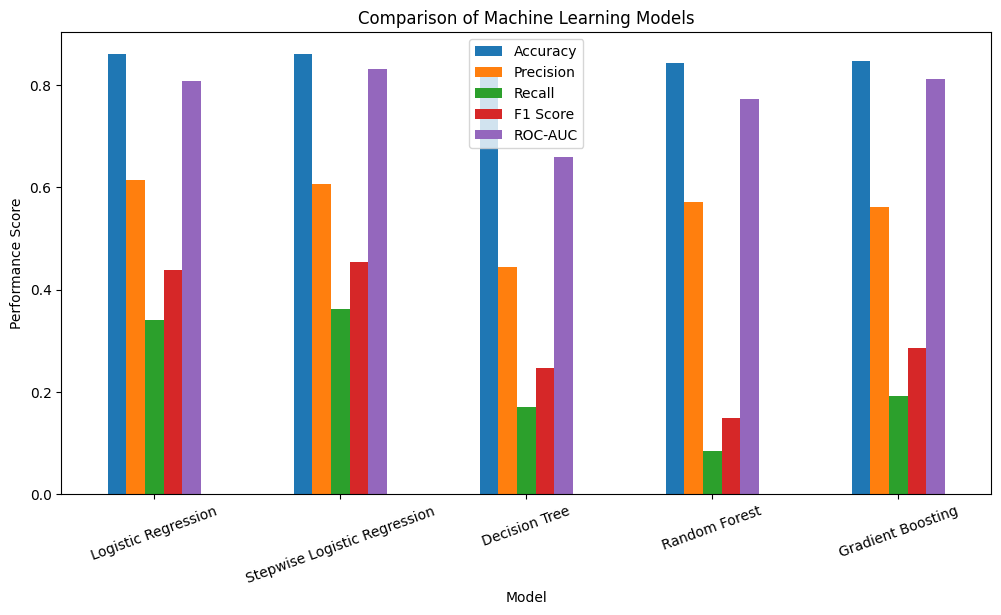

In [105]:
model_results.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparison of Machine Learning Models')
plt.xlabel('Model')
plt.ylabel('Performance Score')
plt.xticks(rotation=20)
plt.legend()
plt.show()

Confusion Matrix for Each Model

In [106]:
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(model_name, y_true, y_pred):

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))

    plt.imshow(cm)
    plt.colorbar()

    plt.xticks([0, 1], ['Stayed', 'Left'])
    plt.yticks([0, 1], ['Stayed', 'Left'])

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {model_name}')

    for i in range(2):
        for j in range(2):
            plt.text(
                j, i, cm[i, j],
                ha='center',
                va='center'
            )

    plt.show()

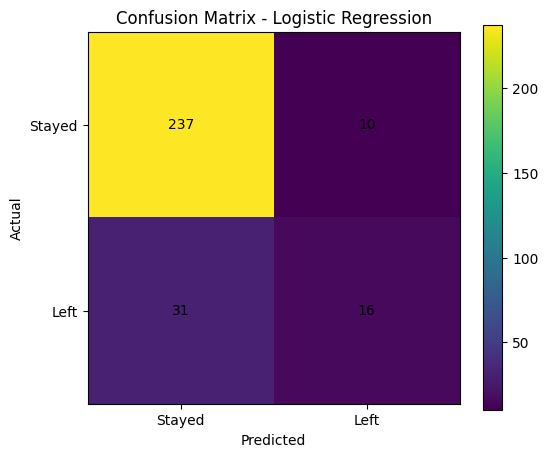

In [107]:
plot_confusion_matrix(
    'Logistic Regression',
    y_test,
    y_pred_log
)

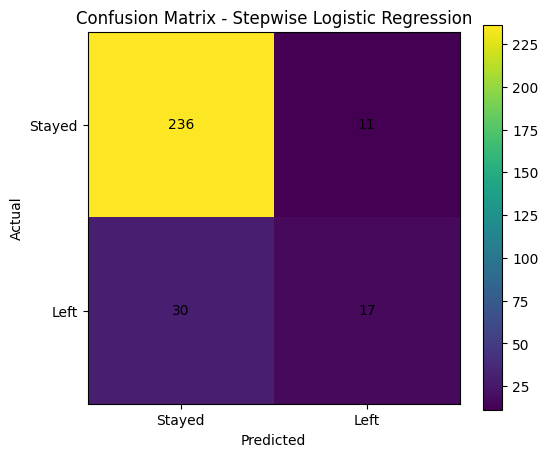

In [108]:
plot_confusion_matrix(
    'Stepwise Logistic Regression',
    y_test,
    y_pred_stepwise
)

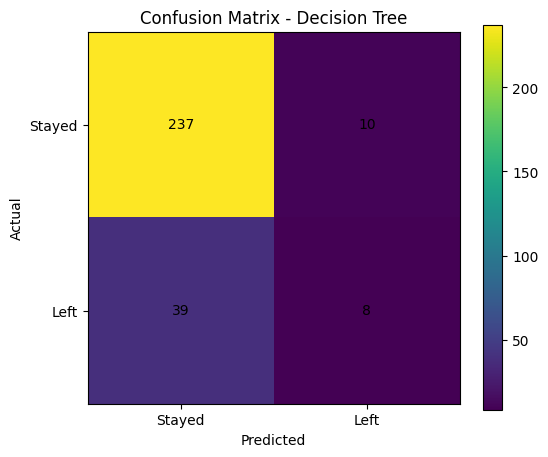

In [109]:
plot_confusion_matrix(
    'Decision Tree',
    y_test,
    y_pred_tree
)

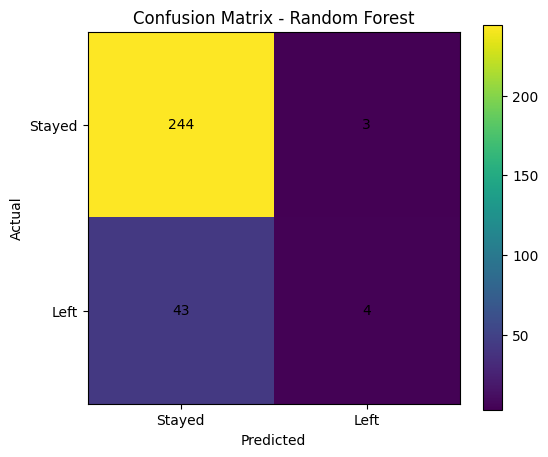

In [110]:
plot_confusion_matrix(
    'Random Forest',
    y_test,
    y_pred_rf
)

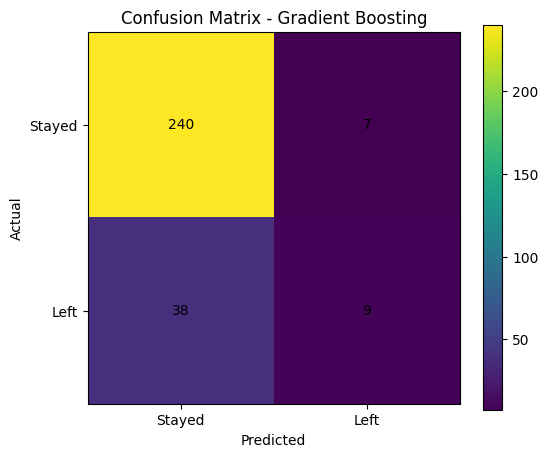

In [111]:
plot_confusion_matrix(
    'Gradient Boosting',
    y_test,
    y_pred_gb
)

ROC Curve Comparison

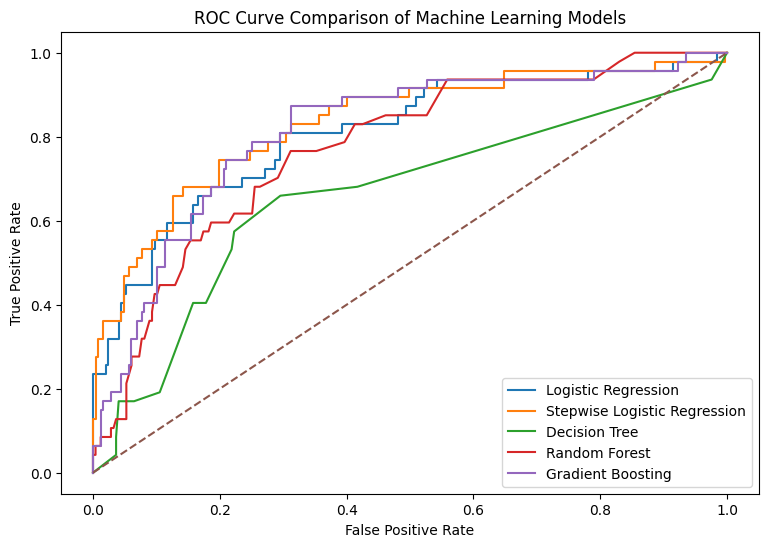

In [112]:
from sklearn.metrics import roc_curve

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_step, tpr_step, _ = roc_curve(y_test, y_prob_stepwise)
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)

plt.figure(figsize=(9, 6))

plt.plot(fpr_log, tpr_log, label='Logistic Regression')
plt.plot(fpr_step, tpr_step, label='Stepwise Logistic Regression')
plt.plot(fpr_tree, tpr_tree, label='Decision Tree')
plt.plot(fpr_rf, tpr_rf, label='Random Forest')
plt.plot(fpr_gb, tpr_gb, label='Gradient Boosting')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Machine Learning Models')

plt.legend()
plt.show()

Random Forest Feature Importance

In [113]:
feature_importance_rf = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance_rf

MonthlyIncome                       0.073667
Age                                 0.063025
TotalWorkingYears                   0.057111
DailyRate                           0.055380
HourlyRate                          0.048220
MonthlyRate                         0.046875
YearsAtCompany                      0.044896
DistanceFromHome                    0.044755
OverTime_Yes                        0.043607
YearsWithCurrManager                0.041417
NumCompaniesWorked                  0.038979
StockOptionLevel                    0.034805
PercentSalaryHike                   0.031582
YearsInCurrentRole                  0.029843
JobSatisfaction                     0.028493
JobLevel                            0.027946
EnvironmentSatisfaction             0.027352
YearsSinceLastPromotion             0.023083
TrainingTimesLastYear               0.022506
WorkLifeBalance                     0.022117
RelationshipSatisfaction            0.021442
JobInvolvement                      0.019927
Education 

In [114]:
feature_importance_rf.head(10)

MonthlyIncome           0.073667
Age                     0.063025
TotalWorkingYears       0.057111
DailyRate               0.055380
HourlyRate              0.048220
MonthlyRate             0.046875
YearsAtCompany          0.044896
DistanceFromHome        0.044755
OverTime_Yes            0.043607
YearsWithCurrManager    0.041417
dtype: float64

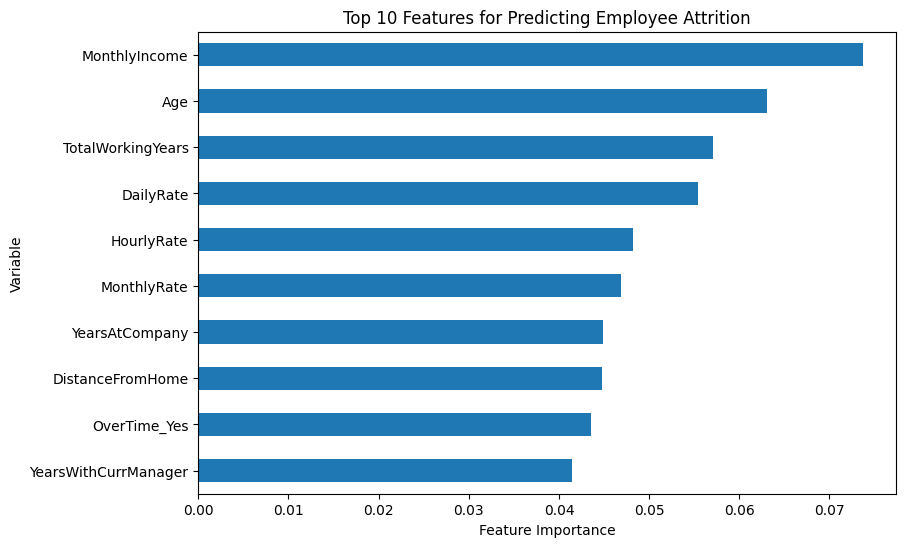

In [115]:
plt.figure(figsize=(9, 6))

feature_importance_rf.head(10).sort_values().plot(
    kind='barh'
)

plt.title('Top 10 Features for Predicting Employee Attrition')
plt.xlabel('Feature Importance')
plt.ylabel('Variable')

plt.show()

Gradient Boosting Feature Importance

In [116]:
feature_importance_gb = pd.Series(
    gb_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance_gb

MonthlyIncome                       0.112772
Age                                 0.105683
TotalWorkingYears                   0.091240
OverTime_Yes                        0.084915
StockOptionLevel                    0.048865
NumCompaniesWorked                  0.045423
DailyRate                           0.045226
YearsWithCurrManager                0.044220
EnvironmentSatisfaction             0.036216
DistanceFromHome                    0.036213
JobInvolvement                      0.035724
HourlyRate                          0.030619
JobRole_Sales Executive             0.028576
JobSatisfaction                     0.026414
WorkLifeBalance                     0.024411
JobRole_Research Scientist          0.023358
MonthlyRate                         0.021073
JobLevel                            0.021066
TrainingTimesLastYear               0.020620
BusinessTravel_Travel_Frequently    0.019118
YearsAtCompany                      0.015451
YearsSinceLastPromotion             0.014911
JobRole_La

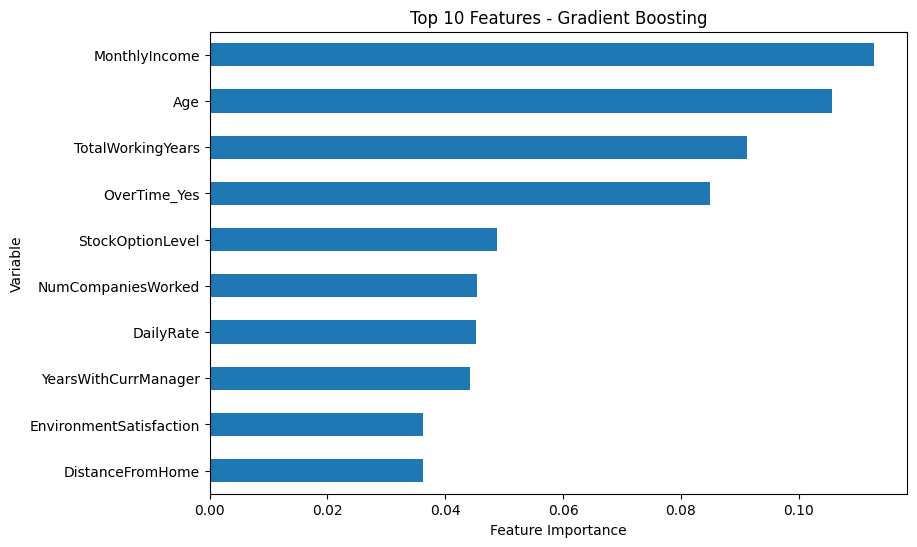

In [117]:
plt.figure(figsize=(9, 6))

feature_importance_gb.head(10).sort_values().plot(
    kind='barh'
)

plt.title('Top 10 Features - Gradient Boosting')
plt.xlabel('Feature Importance')
plt.ylabel('Variable')

plt.show()

In [118]:
feature_comparison = pd.DataFrame({
    'Random Forest': feature_importance_rf,
    'Gradient Boosting': feature_importance_gb
}).sort_values(
    'Random Forest',
    ascending=False
)

feature_comparison.head(10)

,Random Forest,Gradient Boosting
MonthlyIncome,0.073667,0.112772
Age,0.063025,0.105683
TotalWorkingYears,0.057111,0.091240
DailyRate,0.055380,0.045226
HourlyRate,0.048220,0.030619
MonthlyRate,0.046875,0.021073
YearsAtCompany,0.044896,0.015451
DistanceFromHome,0.044755,0.036213
OverTime_Yes,0.043607,0.084915
YearsWithCurrManager,0.041417,0.044220


Identify the Best Model

In [119]:
best_model_auc = model_results.loc[
    model_results['ROC-AUC'].idxmax()
]

best_model_auc

Model        Stepwise Logistic Regression
Accuracy                         0.860544
Precision                        0.607143
Recall                           0.361702
F1 Score                         0.453333
ROC-AUC                          0.832027
Name: 1, dtype: object

In [120]:
best_model_f1 = model_results.loc[
    model_results['F1 Score'].idxmax()
]

best_model_f1

Model        Stepwise Logistic Regression
Accuracy                         0.860544
Precision                        0.607143
Recall                           0.361702
F1 Score                         0.453333
ROC-AUC                          0.832027
Name: 1, dtype: object

## Business Interpretation

The analysis aims to identify the factors associated with employee attrition and develop machine learning models capable of predicting employees who are likely to leave.

The Logistic Regression analysis provides interpretable results through coefficients, odds ratios and statistical significance. The machine learning models are then compared using accuracy, precision, recall, F1-score and ROC-AUC.

The final model should be selected based not only on overall accuracy but also on its ability to correctly identify employees who are likely to leave. From an HR perspective, recall is particularly relevant because failing to identify an employee at risk of leaving may result in a missed retention opportunity.

The feature importance analysis helps identify the variables that contribute most strongly to the predictive performance of the tree-based models. These findings can support targeted employee retention strategies.

## Conclusion

The study used exploratory data analysis, statistical analysis and machine learning techniques to understand and predict employee attrition.

Logistic Regression was used to understand the relationship between employee characteristics and attrition through odds ratios and statistical significance. Stepwise Logistic Regression was additionally used to identify a more parsimonious set of predictors.

Decision Tree, Random Forest and Gradient Boosting models were developed to compare predictive performance. The models were evaluated using accuracy, precision, recall, F1-score and ROC-AUC.

The results provide data-driven insights that can help an organisation identify employees who are more likely to leave and design targeted employee retention strategies.